# Búsqueda no informada: BFS y DFS

Formulación de tres acertijos clásicos como problemas de búsqueda y su solución con búsqueda en anchura (BFS) y en profundidad (DFS), comparando la longitud de la solución y los nodos expandidos:

1. Ranas saltarinas.
2. Jarras de agua.
3. Misioneros y caníbales.

## 1. Marco común

`SearchProblem` define un problema (estado inicial, acciones, resultado de una acción y prueba de objetivo) y `Node` guarda un estado junto con el nodo padre y la acción que lo produjo, para reconstruir el camino. Ambas clases son la base del curso; los problemas heredan de `SearchProblem`.

BFS saca de la frontera el nodo más antiguo (cola) y DFS el más reciente (pila). Los dos llevan un conjunto de estados ya expandidos para no repetirlos.

In [1]:
from collections import deque
import pandas as pd
import matplotlib.pyplot as plt


class SearchProblem:
    """Problema formal: estado inicial, acciones, resultado y prueba de objetivo."""

    def __init__(self, initial, goal=None):
        self.initial = initial
        self.goal = goal

    def actions(self, state):
        raise NotImplementedError

    def result(self, state, action):
        raise NotImplementedError

    def is_goal(self, state):
        return state == self.goal


class Node:
    """Nodo del árbol de búsqueda."""

    def __init__(self, state, parent=None, action=None):
        self.state = state
        self.parent = parent
        self.action = action

    def path(self):
        nodo, camino = self, []
        while nodo:
            camino.append(nodo)
            nodo = nodo.parent
        return camino[::-1]

    def actions_path(self):
        return [n.action for n in self.path()[1:]]


def expand(problem, node):
    return [Node(problem.result(node.state, a), node, a) for a in problem.actions(node.state)]


def search(problem, estrategia):
    """BFS si estrategia == 'bfs', DFS si es 'dfs'. Devuelve (nodo solución, nodos expandidos)."""
    frontera = deque([Node(problem.initial)])
    expandidos = set()
    while frontera:
        nodo = frontera.popleft() if estrategia == 'bfs' else frontera.pop()
        if problem.is_goal(nodo.state):
            return nodo, len(expandidos)
        if nodo.state in expandidos:
            continue
        expandidos.add(nodo.state)
        for hijo in expand(problem, nodo):
            if hijo.state not in expandidos:
                frontera.append(hijo)
    return None, len(expandidos)


resultados = []

def resolver(nombre, problem, mostrar=lambda s: s):
    for estrategia in ('bfs', 'dfs'):
        solucion, expandidos = search(problem, estrategia)
        pasos = len(solucion.actions_path())
        resultados.append({'problema': nombre, 'algoritmo': estrategia.upper(),
                           'pasos': pasos, 'nodos expandidos': expandidos})
        print(f'{estrategia.upper()}: {pasos} pasos, {expandidos} nodos expandidos')
        print('   ' + ' → '.join(str(mostrar(n.state)) for n in solucion.path()))

## 2. Ranas saltarinas

Hay `N` ranas azules (`A`) a la izquierda, un espacio vacío (`.`) y `N` ranas rojas (`R`) a la derecha. Las azules solo avanzan hacia la derecha y las rojas hacia la izquierda; cada rana puede moverse al espacio vacío contiguo o saltar sobre una rana hacia él. El objetivo es intercambiar los dos grupos: de `AA.RR` a `RR.AA`.

El estado es la cadena y una acción es la posición de la rana que se mueve.

In [2]:
class RanasProblem(SearchProblem):

    def __init__(self, n):
        super().__init__('A' * n + '.' + 'R' * n, 'R' * n + '.' + 'A' * n)

    def actions(self, state):
        vacio = state.index('.')
        acciones = []
        for origen in (vacio - 1, vacio - 2):      # azules avanzan a la derecha
            if origen >= 0 and state[origen] == 'A':
                acciones.append(origen)
        for origen in (vacio + 1, vacio + 2):      # rojas avanzan a la izquierda
            if origen < len(state) and state[origen] == 'R':
                acciones.append(origen)
        return acciones

    def result(self, state, action):
        vacio = state.index('.')
        s = list(state)
        s[vacio], s[action] = s[action], '.'
        return ''.join(s)


for n in (2, 3):
    print(f'N = {n}')
    resolver(f'Ranas (N = {n})', RanasProblem(n))

N = 2
BFS: 8 pasos, 22 nodos expandidos
   AA.RR → A.ARR → ARA.R → ARAR. → AR.RA → .RARA → R.ARA → RRA.A → RR.AA
DFS: 8 pasos, 14 nodos expandidos
   AA.RR → AAR.R → A.RAR → .ARAR → RA.AR → RARA. → RAR.A → R.RAA → RR.AA
N = 3
BFS: 15 pasos, 71 nodos expandidos
   AAA.RRR → AA.ARRR → AARA.RR → AARAR.R → AAR.RAR → A.RARAR → .ARARAR → RA.ARAR → RARA.AR → RARARA. → RARAR.A → RAR.RAA → R.RARAA → RR.ARAA → RRRA.AA → RRR.AAA
DFS: 15 pasos, 35 nodos expandidos
   AAA.RRR → AAAR.RR → AA.RARR → A.ARARR → ARA.ARR → ARARA.R → ARARAR. → ARAR.RA → AR.RARA → .RARARA → R.ARARA → RRA.ARA → RRARA.A → RRAR.AA → RR.RAAA → RRR.AAA


## 3. Jarras de agua

Hay una jarra de 3 litros y otra de 5, sin marcas, y un grifo. Se pueden llenar, vaciar o pasar agua de una a otra hasta que una se llene o la otra se vacíe. El objetivo es medir exactamente 4 litros, empezando con las dos jarras vacías.

El estado es `(litros en la de 3, litros en la de 5)`; el objetivo se cumple cuando alguna jarra tiene 4 litros (solo puede ser la de 5).

In [3]:
class JarrasProblem(SearchProblem):
    CAPACIDAD = (3, 5)

    def __init__(self, objetivo=4):
        super().__init__((0, 0), objetivo)

    def actions(self, state):
        a, b = state
        ca, cb = self.CAPACIDAD
        acciones = []
        if a < ca: acciones.append('llenar 3')
        if b < cb: acciones.append('llenar 5')
        if a > 0: acciones.append('vaciar 3')
        if b > 0: acciones.append('vaciar 5')
        if a > 0 and b < cb: acciones.append('pasar 3→5')
        if b > 0 and a < ca: acciones.append('pasar 5→3')
        return acciones

    def result(self, state, action):
        a, b = state
        ca, cb = self.CAPACIDAD
        if action == 'llenar 3': return (ca, b)
        if action == 'llenar 5': return (a, cb)
        if action == 'vaciar 3': return (0, b)
        if action == 'vaciar 5': return (a, 0)
        if action == 'pasar 3→5':
            x = min(a, cb - b)
            return (a - x, b + x)
        x = min(b, ca - a)
        return (a + x, b - x)

    def is_goal(self, state):
        return self.goal in state


resolver('Jarras', JarrasProblem())

BFS: 6 pasos, 13 nodos expandidos
   (0, 0) → (0, 5) → (3, 2) → (0, 2) → (2, 0) → (2, 5) → (3, 4)
DFS: 10 pasos, 10 nodos expandidos
   (0, 0) → (0, 5) → (3, 2) → (3, 0) → (0, 3) → (3, 3) → (1, 5) → (1, 0) → (0, 1) → (3, 1) → (0, 4)


In [4]:
for estrategia in ('bfs', 'dfs'):
    solucion, _ = search(JarrasProblem(), estrategia)
    print(estrategia.upper() + ':', ', '.join(solucion.actions_path()))

BFS: llenar 5, pasar 5→3, vaciar 3, pasar 5→3, llenar 5, pasar 5→3
DFS: llenar 5, pasar 5→3, vaciar 5, pasar 3→5, llenar 3, pasar 3→5, vaciar 5, pasar 3→5, llenar 3, pasar 3→5


## 4. Misioneros y caníbales

Tres misioneros y tres caníbales deben cruzar un río en un bote de una o dos personas. En ninguna orilla los misioneros presentes pueden quedar en minoría frente a los caníbales, y el bote no cruza vacío.

El estado es `(misioneros en la orilla inicial, caníbales en la orilla inicial, orilla del bote)`; la otra orilla se deduce.

In [5]:
class MisionerosProblem(SearchProblem):
    VIAJES = [(1, 0), (2, 0), (0, 1), (0, 2), (1, 1)]   # (misioneros, caníbales) en el bote

    def __init__(self, n=3):
        self.n = n
        super().__init__((n, n, 'inicial'), (0, 0, 'final'))

    def valido(self, m, c):
        if not (0 <= m <= self.n and 0 <= c <= self.n):
            return False
        otra_m, otra_c = self.n - m, self.n - c
        return (m == 0 or m >= c) and (otra_m == 0 or otra_m >= otra_c)

    def actions(self, state):
        m, c, bote = state
        signo = -1 if bote == 'inicial' else 1
        return [(dm, dc) for dm, dc in self.VIAJES if self.valido(m + signo * dm, c + signo * dc)]

    def result(self, state, action):
        m, c, bote = state
        signo = -1 if bote == 'inicial' else 1
        return (m + signo * action[0], c + signo * action[1],
                'final' if bote == 'inicial' else 'inicial')


def orillas(state):
    m, c, bote = state
    return f"{'M' * m}{'C' * c}|{'M' * (3 - m)}{'C' * (3 - c)}"

resolver('Misioneros y caníbales', MisionerosProblem(), mostrar=orillas)

BFS: 11 pasos, 14 nodos expandidos
   MMMCCC| → MMMC|CC → MMMCC|C → MMM|CCC → MMMC|CC → MC|MMCC → MMCC|MC → CC|MMMC → CCC|MMM → C|MMMCC → MC|MMCC → |MMMCCC
DFS: 11 pasos, 11 nodos expandidos
   MMMCCC| → MMCC|MC → MMMCC|C → MMM|CCC → MMMC|CC → MC|MMCC → MMCC|MC → CC|MMMC → CCC|MMM → C|MMMCC → CC|MMMC → |MMMCCC


## 5. Comparación

,problema,algoritmo,pasos,nodos expandidos
0,Ranas (N = 2),BFS,8,22
1,Ranas (N = 2),DFS,8,14
2,Ranas (N = 3),BFS,15,71
3,Ranas (N = 3),DFS,15,35
4,Jarras,BFS,6,13
5,Jarras,DFS,10,10
6,Misioneros y caníbales,BFS,11,14
7,Misioneros y caníbales,DFS,11,11


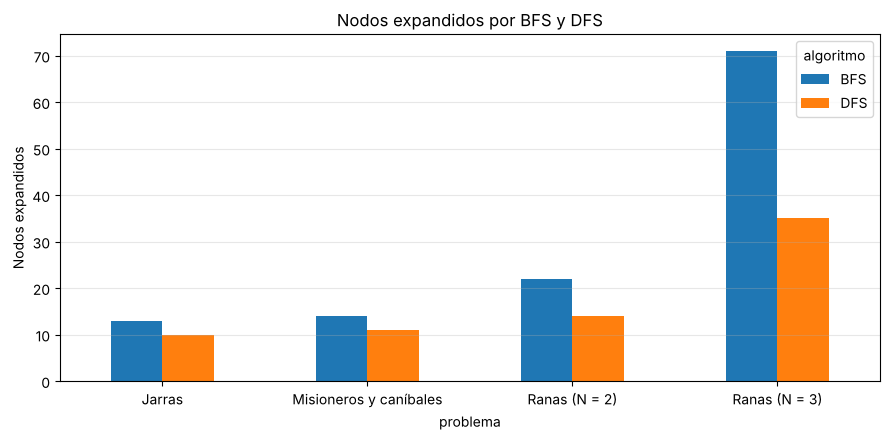

In [6]:
tabla = pd.DataFrame(resultados)
display(tabla)

pivote = tabla.pivot(index='problema', columns='algoritmo', values='nodos expandidos')
pivote.plot(kind='bar', figsize=(9, 4.5), rot=0)
plt.ylabel('Nodos expandidos')
plt.title('Nodos expandidos por BFS y DFS')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Análisis**

- BFS siempre encuentra la solución con menos pasos, porque explora el árbol por niveles. En las ranas (8 pasos con N = 2 y 15 con N = 3, el mínimo N² + 2N) y en misioneros y caníbales (11 cruces) DFS también llega al mínimo, porque todas las soluciones de esos acertijos tienen la misma longitud.
- En las jarras sí se nota la diferencia: BFS mide los 4 litros en 6 pasos y DFS en 10, siguiendo la primera rama que encuentra.
- DFS expande menos nodos en los cuatro casos: va directo por una rama mientras BFS completa cada nivel. La ventaja crece con el tamaño del problema: en las ranas con N = 3, BFS expande el doble de nodos (71 frente a 35).
- El costo de BFS es la memoria: guarda en la frontera todos los nodos de un nivel antes de pasar al siguiente. Para espacios de estados pequeños como estos, ambos algoritmos resuelven al instante.